# X-IIoTID — Extra Trees (separate model notebook)

**V2 provisional Core-19 network benchmark.** Uses frozen 70/15/15 Core-19 group-disjoint split. Fits preprocessing **only on train**, evaluates **only on validation**, exports confusion matrix, feature importance (where provided), timing, model and metrics.

To run: first execute Notebook **07**, then this notebook. All five models use the same **150,000-row stratified subset of training** for a fair, laptop-friendly pilot; the full **123,125-row validation** is used. You may later change `TRAIN_LIMIT` to `None` in *all five* notebooks for full-training comparisons. The 70/15/15 partition membership is never changed.

**Limitations:** Inputs' gateway measurability and session independence have not been verified. This is not an APT-campaign detector. Reported timing is **laptop timing**, not Raspberry Pi inference.


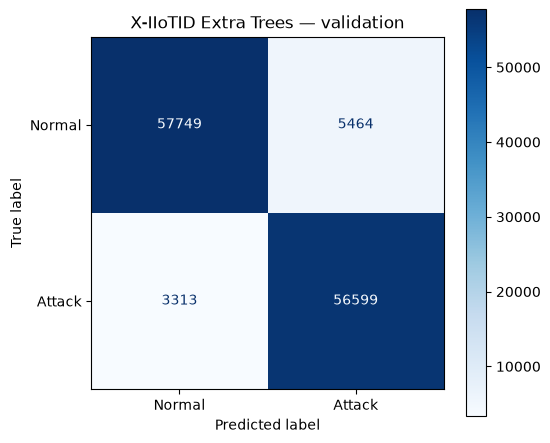

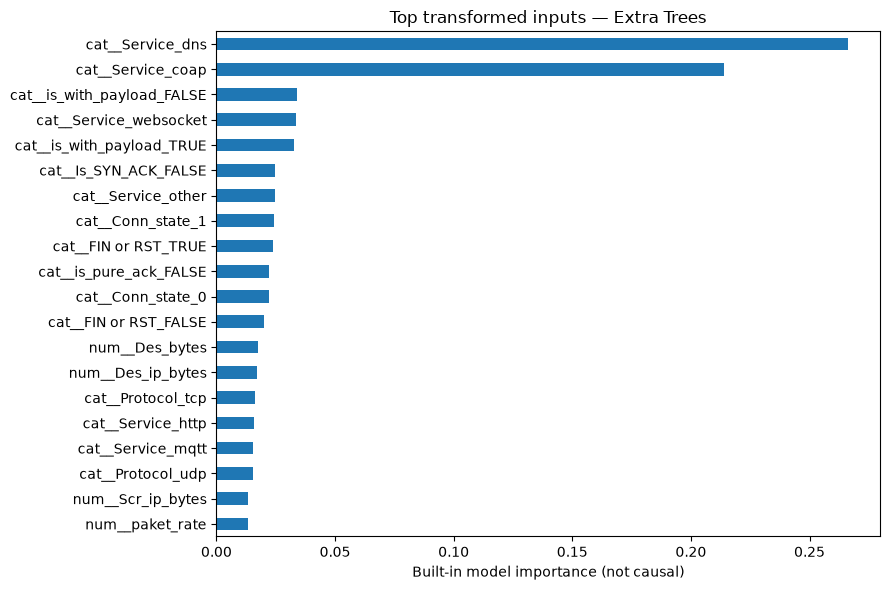


EXTRA_TREES VALIDATION METRICS — TEST NOT OPENED
      model  train_rows_used  validation_rows  precision_attack  recall_attack  f1_attack  balanced_accuracy  false_positive_rate  fit_seconds  predict_ms_per_1000
extra_trees           574585           123125            0.9120         0.9447     0.9280             0.9291               0.0864      30.6390               7.2720
Saved model (local, Git-ignored): D:\J26-CS-336-Network-Flow-V2\network_flow_v2\models\x_iiotid\extra_trees_core19_v1.joblib
Saved validation metrics and PNG charts in reports/
{'model': 'extra_trees', 'features': 'Core19', 'train_rows_used': 574585, 'validation_rows': 123125, 'precision_attack': 0.9119604273077356, 'recall_attack': 0.9447022299372413, 'f1_attack': 0.9280426316868211, 'balanced_accuracy': 0.9291321568429187, 'false_positive_rate': 0.08643791625140398, 'tn': 57749, 'fp': 5464, 'fn': 3313, 'tp': 56599, 'fit_seconds': 30.639, 'predict_ms_per_1000': 7.272, 'random_seed': 42, 'frozen_manifest_sha256': '

In [3]:
from pathlib import Path
import sys

ROOT = Path(
    r"D:\J26-CS-336-Network-Flow-V2\network_flow_v2"
)

assert ROOT.is_dir(), f"Folder not found: {ROOT}"

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from x_iiotid_model_runner import execute

# None means use the entire frozen training dataset
TRAIN_LIMIT = None

metrics = execute(
    ROOT,
    "extra_trees",
    train_limit=TRAIN_LIMIT
)

print(metrics)

Outputs:
- `reports/audits/x_iiotid_extra_trees_validation_v1.csv` and `.json`
- `reports/figures/x_iiotid_extra_trees_validation_cm_v1.png`
- Feature-importance chart when estimator supports it
- `models/x_iiotid/extra_trees_core19_v1.joblib` (local; Git ignored)

Never run an evaluation on `test` in this notebook. Compare validation metrics across all models in Notebook 13.
